In [1]:
print("notebook works!")

notebook works!


In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/Wednesday-workingHours.pcap_ISCX.csv")
df.shape

(692703, 79)

In [3]:
df.head()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,80,38308,1,1,6,6,6,6,6.000000,0.000000,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,389,479,11,5,172,326,79,0,15.636364,31.449238,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,88,1095,10,6,3150,3150,1575,0,315.000000,632.561635,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,389,15206,17,12,3452,6660,1313,0,203.058823,425.778474,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,88,1092,9,6,3150,3152,1575,0,350.000000,694.509719,...,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [4]:
df.columns = df.columns.str.strip()
list(df.columns)

['Destination Port',
 'Flow Duration',
 'Total Fwd Packets',
 'Total Backward Packets',
 'Total Length of Fwd Packets',
 'Total Length of Bwd Packets',
 'Fwd Packet Length Max',
 'Fwd Packet Length Min',
 'Fwd Packet Length Mean',
 'Fwd Packet Length Std',
 'Bwd Packet Length Max',
 'Bwd Packet Length Min',
 'Bwd Packet Length Mean',
 'Bwd Packet Length Std',
 'Flow Bytes/s',
 'Flow Packets/s',
 'Flow IAT Mean',
 'Flow IAT Std',
 'Flow IAT Max',
 'Flow IAT Min',
 'Fwd IAT Total',
 'Fwd IAT Mean',
 'Fwd IAT Std',
 'Fwd IAT Max',
 'Fwd IAT Min',
 'Bwd IAT Total',
 'Bwd IAT Mean',
 'Bwd IAT Std',
 'Bwd IAT Max',
 'Bwd IAT Min',
 'Fwd PSH Flags',
 'Bwd PSH Flags',
 'Fwd URG Flags',
 'Bwd URG Flags',
 'Fwd Header Length',
 'Bwd Header Length',
 'Fwd Packets/s',
 'Bwd Packets/s',
 'Min Packet Length',
 'Max Packet Length',
 'Packet Length Mean',
 'Packet Length Std',
 'Packet Length Variance',
 'FIN Flag Count',
 'SYN Flag Count',
 'RST Flag Count',
 'PSH Flag Count',
 'ACK Flag Count',
 'UR

In [5]:
df["Label"].value_counts()

Label
BENIGN              440031
DoS Hulk            231073
DoS GoldenEye        10293
DoS slowloris         5796
DoS Slowhttptest      5499
Heartbleed              11
Name: count, dtype: int64

In [6]:
df = df.replace([np.inf, -np.inf], np.nan)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 2594
Duplicate rows: 81909


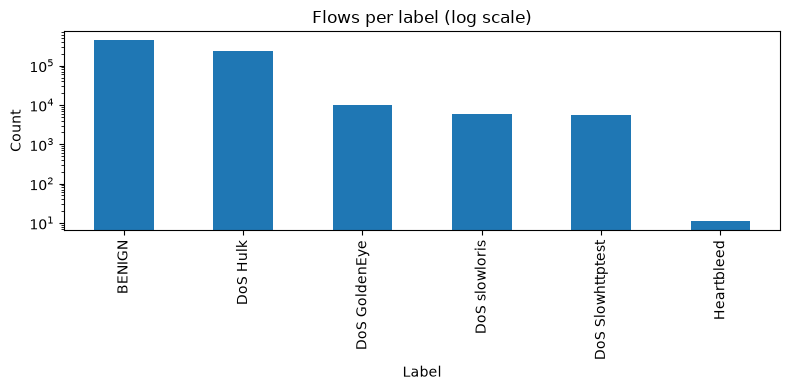

In [7]:
import matplotlib.pyplot as plt

df["Label"].value_counts().plot(kind="bar", figsize=(8, 4), logy=True)
plt.title("Flows per label (log scale)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [8]:
before = len(df)
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna()
print("Rows removed (missing/infinite):", before - len(df))

Rows removed (missing/infinite): 1297


In [9]:
before = len(df)
df = df.drop_duplicates()
print("Rows removed (duplicates):", before - len(df))
print("Rows left:", len(df))

Rows removed (duplicates): 80914
Rows left: 610492


In [10]:
df["Label"].value_counts()

Label
BENIGN              416736
DoS Hulk            172846
DoS GoldenEye        10286
DoS slowloris         5385
DoS Slowhttptest      5228
Heartbleed              11
Name: count, dtype: int64

In [11]:
for i, c in enumerate(df.columns):
    print(i, c)

0 Destination Port
1 Flow Duration
2 Total Fwd Packets
3 Total Backward Packets
4 Total Length of Fwd Packets
5 Total Length of Bwd Packets
6 Fwd Packet Length Max
7 Fwd Packet Length Min
8 Fwd Packet Length Mean
9 Fwd Packet Length Std
10 Bwd Packet Length Max
11 Bwd Packet Length Min
12 Bwd Packet Length Mean
13 Bwd Packet Length Std
14 Flow Bytes/s
15 Flow Packets/s
16 Flow IAT Mean
17 Flow IAT Std
18 Flow IAT Max
19 Flow IAT Min
20 Fwd IAT Total
21 Fwd IAT Mean
22 Fwd IAT Std
23 Fwd IAT Max
24 Fwd IAT Min
25 Bwd IAT Total
26 Bwd IAT Mean
27 Bwd IAT Std
28 Bwd IAT Max
29 Bwd IAT Min
30 Fwd PSH Flags
31 Bwd PSH Flags
32 Fwd URG Flags
33 Bwd URG Flags
34 Fwd Header Length
35 Bwd Header Length
36 Fwd Packets/s
37 Bwd Packets/s
38 Min Packet Length
39 Max Packet Length
40 Packet Length Mean
41 Packet Length Std
42 Packet Length Variance
43 FIN Flag Count
44 SYN Flag Count
45 RST Flag Count
46 PSH Flag Count
47 ACK Flag Count
48 URG Flag Count
49 CWE Flag Count
50 ECE Flag Count
51 Down/

In [12]:
if "Destination Port" in df.columns:
    attacks = df[df["Label"] != "BENIGN"]
    print("Top destination ports in ATTACK flows:")
    print(attacks["Destination Port"].value_counts().head(5))
    print()
    print("Top destination ports in NORMAL flows:")
    print(df[df["Label"] == "BENIGN"]["Destination Port"].value_counts().head(5))

Top destination ports in ATTACK flows:
Destination Port
80     193745
444        11
Name: count, dtype: int64

Top destination ports in NORMAL flows:
Destination Port
53     184489
443     93669
80      45979
123      4100
22       1484
Name: count, dtype: int64


In [13]:
drop_cols = [
    "Flow ID", "Source IP", "Destination IP", "Source Port",
    "Destination Port", "Timestamp", "Fwd Header Length.1",
]
# Only drop the ones that actually exist in your file
drop_cols = [c for c in drop_cols if c in df.columns]
print("Dropping:", drop_cols)

df = df.drop(columns=drop_cols)

Dropping: ['Destination Port', 'Fwd Header Length.1']


In [14]:
constant_cols = [c for c in df.columns if c != "Label" and df[c].nunique() <= 1]
print("Constant columns:", constant_cols)
df = df.drop(columns=constant_cols)
print("Columns left:", df.shape[1])

Constant columns: ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Columns left: 67


In [15]:
df["target"] = (df["Label"] != "BENIGN").astype(int)   # 0 = normal, 1 = attack
print(df["target"].value_counts())
print()
print("Share of attacks: {:.1%}".format(df["target"].mean()))

target
0    416736
1    193756
Name: count, dtype: int64

Share of attacks: 31.7%


In [16]:
from sklearn.model_selection import train_test_split

feature_cols = [c for c in df.columns if c not in ("Label", "target")]
X = df[feature_cols]
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows: ", len(X_test))
print("Number of features:", len(feature_cols))

Training rows: 488393
Testing rows:  122099
Number of features: 66


In [17]:
import json, os

os.makedirs("../models", exist_ok=True)
with open("../models/feature_columns.json", "w") as f:
    json.dump(feature_cols, f, indent=2)

print("Saved", len(feature_cols), "feature names.")

Saved 66 feature names.


In [18]:
lazy = (y_test == 0).mean()
print("A model that always says 'normal' scores: {:.1%}".format(lazy))
print("Share of attacks in test set: {:.1%}".format(y_test.mean()))

A model that always says 'normal' scores: 68.3%
Share of attacks in test set: 31.7%


In [19]:
from sklearn.ensemble import RandomForestClassifier
import time

start = time.time()
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
print("Training took {:.0f} seconds".format(time.time() - start))

Training took 37 seconds


In [20]:
from sklearn.metrics import classification_report, confusion_matrix

pred = rf.predict(X_test)
print(classification_report(y_test, pred, target_names=["normal", "attack"], digits=4))
print(confusion_matrix(y_test, pred))

              precision    recall  f1-score   support

      normal     0.9992    0.9990    0.9991     83348
      attack     0.9979    0.9982    0.9981     38751

    accuracy                         0.9988    122099
   macro avg     0.9985    0.9986    0.9986    122099
weighted avg     0.9988    0.9988    0.9988    122099

[[83266    82]
 [   69 38682]]


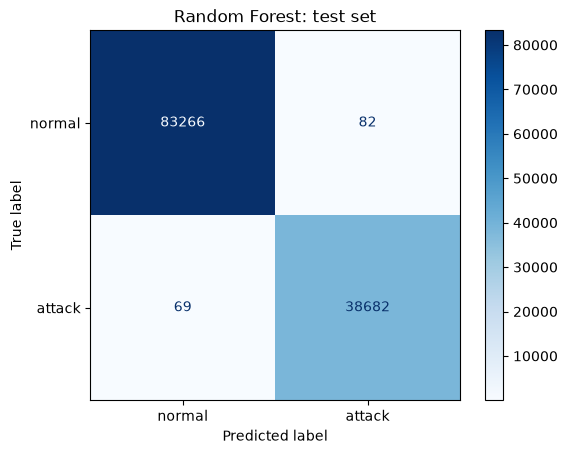

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["normal", "attack"], cmap="Blues", values_format="d"
)
plt.title("Random Forest: test set")
plt.show()

Bwd Packet Length Mean         0.128977
Avg Bwd Segment Size           0.104784
Bwd Packet Length Max          0.102494
Packet Length Std              0.066648
Bwd Packet Length Std          0.065542
Max Packet Length              0.057667
Packet Length Mean             0.048494
Average Packet Size            0.041479
Packet Length Variance         0.035819
Subflow Bwd Bytes              0.033277
Fwd IAT Mean                   0.023100
Flow IAT Mean                  0.020576
Fwd IAT Max                    0.019848
Flow Packets/s                 0.018428
Total Length of Bwd Packets    0.017074
dtype: float64


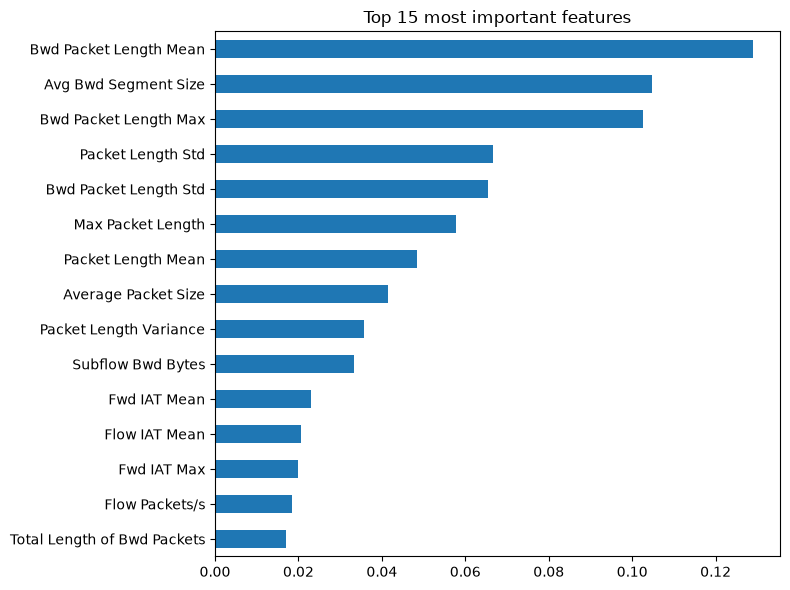

In [22]:
import pandas as pd

importance = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
print(importance.head(15))

importance.head(15).sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("Top 15 most important features")
plt.tight_layout()
plt.show()

In [23]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, recall_score, f1_score

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": rf,
}

rows = []
for name, m in models.items():
    if name != "Random Forest":
        m.fit(X_train, y_train)
    p = m.predict(X_test)
    rows.append({
        "model": name,
        "precision": precision_score(y_test, p),
        "recall": recall_score(y_test, p),
        "f1": f1_score(y_test, p),
    })

results = pd.DataFrame(rows).round(4)
results

,model,precision,recall,f1
0,Decision Tree,0.9987,0.9985,0.9986
1,Logistic Regression,0.9629,0.9776,0.9702
2,Random Forest,0.9979,0.9982,0.9981


In [24]:
raw_port = pd.read_csv(
    "../data/Wednesday-workingHours.pcap_ISCX.csv",
    usecols=lambda c: c.strip() == "Destination Port",
)
raw_port.columns = ["Destination Port"]

# Our cleaned rows kept their original row numbers, so we can line them up
Xtr_port = X_train.join(raw_port)
Xte_port = X_test.join(raw_port)

rf_port = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_port.fit(Xtr_port, y_train)
p2 = rf_port.predict(Xte_port)

print("WITHOUT port: recall {:.4f}, precision {:.4f}".format(
    recall_score(y_test, pred), precision_score(y_test, pred)))
print("WITH port:    recall {:.4f}, precision {:.4f}".format(
    recall_score(y_test, p2), precision_score(y_test, p2)))

WITHOUT port: recall 0.9982, precision 0.9979
WITH port:    recall 0.9989, precision 0.9990


In [25]:
import joblib

joblib.dump({"model": rf, "features": feature_cols}, "../models/nids_rf.joblib")
print("Saved model to models/nids_rf.joblib")

Saved model to models/nids_rf.joblib
